# Window coverage follow-up: results

**Windowing alone did not produce a useful detector.** On 919 fresh BrowseSafe pages, ROC-AUC increased by only 0.007–0.010 across three classifier seeds. All nominal paired bootstrap intervals include zero, and false-positive rates increased substantially.

This report reads the downloaded Colab artifacts; it does not retrain or retune thresholds. The encoder is frozen. Seeds vary XGBoost only.

## Context and methods

Same base MPNet, training rows, classifier parameters and preprocessing. The correction replaces first-window inference with the maximum score over 382-token windows with 96-token overlap. Each operating threshold was frozen using validation balanced accuracy before final scoring.

The final BrowseSafe slice contains 445 attack and 474 non-injection labels after overlap screening. It is distinct from the earlier test set. Known HTML extraction losses, weak/context-dependent labels and source/template dependence remain. No production-security claim is supported.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
evidence = root / 'results/colab_window_followup_20260911/window_followup'
report = json.loads((evidence/'holdout_results.json').read_text())
verification = json.loads((evidence/'verification.json').read_text())
assert verification['status'] == 'passed'
records=[]
for key, r in report['summaries'].items():
    method, seed = key.split('_')
    records.append({'Seed':int(seed),'Method':method,'ROC-AUC':r['roc_auc'],'Recall':r['recall']['value'],'FPR':r['fpr']['value'],'Balanced accuracy':r['balanced_accuracy'],'Threshold':r['threshold']})
table = pd.DataFrame(records).sort_values(['Seed','Method'])
table.round(4)

,Seed,Method,ROC-AUC,Recall,FPR,Balanced accuracy,Threshold
0,17,base,0.5398,0.1708,0.1224,0.5242,0.8157
1,17,windowed,0.5471,0.5124,0.4599,0.5262,0.8367
2,42,base,0.5330,0.1124,0.0696,0.5214,0.8808
3,42,windowed,0.5430,0.4315,0.3608,0.5354,0.8808
4,73,base,0.5331,0.3011,0.2278,0.5366,0.7232
5,73,windowed,0.5412,0.6539,0.6034,0.5253,0.7730


## Fresh holdout results

All seeds are shown; no winning seed was selected. False positives and recall are measured at independently validation-selected thresholds. These are not matched-FPR comparisons.

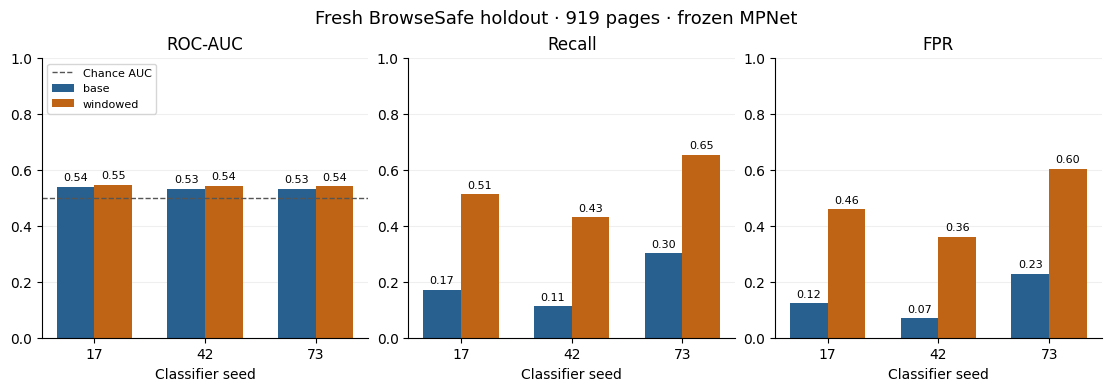

In [2]:
fig, axes = plt.subplots(1,3,figsize=(11,3.8),layout='constrained')
seeds=[17,42,73]
colors=['#286090','#bf6414']
for ax,metric in zip(axes,['ROC-AUC','Recall','FPR']):
    for j,method in enumerate(['base','windowed']):
        values=[table[(table.Seed==s)&(table.Method==method)][metric].iloc[0] for s in seeds]
        bars=ax.bar(np.arange(3)+(j-.5)*.34,values,width=.34,label=method,color=colors[j])
        ax.bar_label(bars,fmt='%.2f',fontsize=8,padding=3)
    ax.set_xticks(range(3),[str(s) for s in seeds]); ax.set_xlabel('Classifier seed')
    ax.set_ylim(0,1); ax.set_title(metric); ax.spines[['top','right']].set_visible(False)
    ax.grid(axis='y',alpha=.2); ax.set_axisbelow(True)
axes[0].axhline(.5,ls='--',color='#555555',linewidth=1,label='Chance AUC')
axes[0].legend(fontsize=8,loc='upper left')
fig.suptitle('Fresh BrowseSafe holdout · 919 pages · frozen MPNet',fontsize=13)
fig.savefig(evidence/'comparison.png',dpi=180)
fig.savefig(evidence/'comparison.pdf')
plt.show()

In [3]:
intervals=verification['paired_auc_intervals']
ci_table=pd.DataFrame([{'Seed':int(s),'AUC delta':r['delta'],'Nominal 95% lower':r['nominal_paired_stratified_bootstrap_95'][0],'Nominal 95% upper':r['nominal_paired_stratified_bootstrap_95'][1]} for s,r in intervals.items()])
ci_table.round(4)

,Seed,AUC delta,Nominal 95% lower,Nominal 95% upper
0,17,0.0073,-0.0305,0.0502
1,42,0.0100,-0.0305,0.0536
2,73,0.0080,-0.0326,0.0532


## Interpretation and limits

The predefined direction-consistency criterion passed, but the gains are small and all nominal 95% intervals include zero. The 1,000-resample paired bootstrap is stratified by label and assumes independent documents; unknown website/template dependence makes these intervals optimistic as generalization evidence.

Windowing increases recall by flagging many more documents, with large false-positive increases. It does not fix HTML attributes/comments removed before tokenization, context-dependent labels, or source/template shortcuts. Retain the base model as a research reference and prioritize faithful input extraction and context-aware label review before further encoder training.

Verification: 30 archive artifact hashes, token coverage and hashes, classifier score replay, original seed-42 validation reproduction, holdout overlap rules and frozen thresholds passed. GPU encoder inference was not independently repeated. The separate portable Colab launcher has not been rerun from a clean runtime; the actual stages ran in the existing Colab session.